# Market Structure Analysis: Sector Factors & BTC/ETH Predictability

This notebook has two independent analyses of daily market data from Yahoo Finance:

1. **Sector factor structure.** PCA (via SVD) on ten years of daily excess returns for 100 large-cap US stocks across the 11 GICS sectors. It looks at what drives co-movement, whether sectors show up as distinct clusters, and how linear (PCA) and nonlinear (t-SNE, UMAP) embeddings compare.
2. **BTC vs ETH relative-return prediction.** Can lagged daily returns predict *which* of Bitcoin or Ethereum will have the higher return tomorrow? Several classifiers are compared against a naive baseline, using a chronological split and walk-forward validation.

**Reproducibility:** all dates and random seeds are fixed in the configuration cell below. Yahoo Finance revises adjusted prices over time (for example when new dividends are paid), so re-running later can shift the numbers slightly.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import umap
import yfinance as yf
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# ---- Configuration ----
SEED = 42
START_DATE = "2016-05-01"
END_DATE = "2026-05-01"      # fixed so results are reproducible
TRADING_DAYS = 252
N_LAGS = 7                   # days of lagged returns used as crypto features

np.random.seed(SEED)
torch.manual_seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*n_jobs value.*")   # UMAP: single-threaded when seeded
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
def download_close(tickers, start=START_DATE, end=END_DATE, allow_missing=False):
    # Auto-adjusted daily closing prices from Yahoo Finance as a (dates x tickers) DataFrame.
    # Tickers with no data (e.g. delisted) raise an error, or are dropped with a warning if allow_missing.
    tickers = [tickers] if isinstance(tickers, str) else list(tickers)
    close = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"]
    if isinstance(close, pd.Series):
        close = close.to_frame(tickers[0])
    missing = [t for t in tickers if t not in close.columns or close[t].isna().all()]
    if missing and not allow_missing:
        raise RuntimeError(f"No data returned for: {missing}")
    if missing:
        print(f"WARNING: no data returned for {missing} (possibly delisted); excluding them.")
    return close[[t for t in tickers if t not in missing]].sort_index()

# Part 1: Sector Factor Structure

## Universe

100 large-cap US stocks: 10 Information Technology names and 9 from each of the other 10 GICS sectors.

> **Survivorship bias:** this list holds companies that are large caps *today*. Picking them in 2026 and looking back to 2016 leaves out firms that shrank, were acquired, or went bankrupt along the way. The goal here is to describe co-movement structure, not to measure performance, so this matters less. Still, the results describe today's winners, not the 2016 market as a whole.

In [3]:
TICKERS_BY_SECTOR = {
    "Information Technology": ["AAPL", "MSFT", "NVDA", "AVGO", "AMD", "ORCL", "CRM", "TXN", "QCOM", "MU"],
    "Financials":             ["JPM", "BAC", "WFC", "GS", "MS", "BLK", "AXP", "CB", "PGR"],
    "Health Care":            ["LLY", "UNH", "JNJ", "ABBV", "MRK", "TMO", "ABT", "AMGN", "GILD"],
    "Consumer Discretionary": ["AMZN", "TSLA", "HD", "MCD", "NKE", "LOW", "SBUX", "TJX", "GM"],
    "Communication Services": ["GOOGL", "META", "NFLX", "DIS", "CMCSA", "T", "VZ", "TMUS", "EA"],
    "Industrials":            ["CAT", "HON", "UNP", "UPS", "BA", "RTX", "DE", "LMT", "GE"],
    "Consumer Staples":       ["PG", "KO", "PEP", "COST", "WMT", "PM", "MO", "CL", "KMB"],
    "Energy":                 ["XOM", "CVX", "COP", "EOG", "SLB", "MPC", "PSX", "VLO", "OXY"],
    "Utilities":              ["NEE", "DUK", "SO", "D", "AEP", "EXC", "XEL", "SRE", "PEG"],
    "Real Estate":            ["PLD", "AMT", "EQIX", "CCI", "SPG", "O", "PSA", "WELL", "AVB"],
    "Materials":              ["LIN", "APD", "SHW", "FCX", "NEM", "NUE", "VMC", "MLM", "ALB"],
}

sector_map = {t: sector for sector, tickers in TICKERS_BY_SECTOR.items() for t in tickers}
tickers_all = list(sector_map)
assert len(tickers_all) == sum(len(v) for v in TICKERS_BY_SECTOR.values()), "duplicate ticker in universe"
print(f"Universe: {len(tickers_all)} tickers across {len(TICKERS_BY_SECTOR)} sectors")

Universe: 100 tickers across 11 sectors


## Data download and quality checks

Missing prices are **not** filled with later values. Back-filling would copy future prices into the past and create artificial zero returns. Instead:
- tickers Yahoo no longer serves (for example, delisted or taken private after the list was made) are dropped and reported;
- tickers whose history starts after the first date (listed late) are dropped and reported;
- any date still missing a price is dropped and reported.

In [4]:
prices = download_close(tickers_all, allow_missing=True)
print(f"Downloaded prices: {prices.shape[0]} days x {prices.shape[1]} tickers "
      f"({prices.index[0].date()} to {prices.index[-1].date()})")

missing_per_ticker = prices.isna().sum()
print("\nMissing values per ticker:",
      "none" if missing_per_ticker.sum() == 0 else "\n" + missing_per_ticker[missing_per_ticker > 0].to_string())

first_valid = prices.apply(pd.Series.first_valid_index)
late_listed = first_valid[first_valid > prices.index[0] + pd.Timedelta(days=7)].index.tolist()
if late_listed:
    print(f"Dropping late-listed tickers: {late_listed}")
    prices = prices.drop(columns=late_listed)

n_before = len(prices)
prices = prices.dropna()
print(f"Dropped {n_before - len(prices)} dates with incomplete prices. Final: {prices.shape}")


2 Failed downloads:
['AVB', 'EA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2016-05-01 -> 2026-05-01) (Yahoo error = "Data doesn\'t exist for startDate = 1462075200, endDate = 1777608000")')


Downloaded prices: 2514 days x 98 tickers (2016-05-02 to 2026-04-30)

Missing values per ticker: none
Dropped 0 dates with incomplete prices. Final: (2514, 98)


## Excess log returns

Daily log returns are $r_t = \log(P_t / P_{t-1})$. The risk-free rate is the 13-week T-bill yield (`^IRX`, annualized percent), converted to a daily log rate as $\log(1 + y/100)/252$ and subtracted from each stock's return. On days with no T-bill quote, the last known rate is carried forward. That uses only past information, so nothing leaks in from the future.

In [5]:
log_returns = np.log(prices / prices.shift(1)).iloc[1:]

irx = download_close("^IRX").squeeze()
rf_daily = (np.log1p(irx / 100) / TRADING_DAYS).reindex(log_returns.index).ffill()

has_rf = rf_daily.notna()
excess_returns = log_returns[has_rf].sub(rf_daily[has_rf], axis=0)
assert not excess_returns.isna().any().any()

print(f"Excess returns: {excess_returns.shape[0]} days x {excess_returns.shape[1]} stocks")
print(f"Mean daily risk-free rate: {rf_daily.mean():.6f} (~{rf_daily.mean() * TRADING_DAYS:.2%} annualized)")

Excess returns: 2513 days x 98 stocks
Mean daily risk-free rate: 0.000088 (~2.22% annualized)


## PCA via SVD

Before the SVD, each stock's excess-return series is **standardized** (mean 0, standard deviation 1):
- **Centering** makes the SVD an actual PCA. Without it, the components partly capture average returns rather than co-movement.
- **Scaling** to unit variance means PCA works on the *correlation* matrix. Otherwise high-volatility names like TSLA, NVDA and AMD would dominate the leading components just because they move more.

With $X$ the standardized $n_{\text{stocks}} \times n_{\text{days}}$ matrix, $X = U \Sigma V^\top$. The rows of $V^\top$ are the component time series, and $U\Sigma$ gives each stock's coordinates (loadings) on the components. SVD signs are arbitrary, so each component is flipped where needed so that its average loading is positive.

PC1: 34.78% of variance
PC2: 8.30% of variance
PC3: 5.61% of variance
First 3 components combined: 48.70%


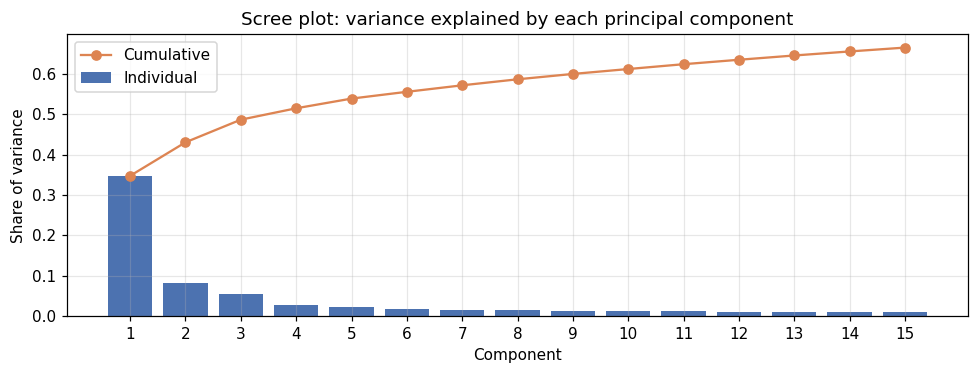

In [6]:
Z = (excess_returns - excess_returns.mean()) / excess_returns.std()
X = Z.T.values                                   # n_stocks x n_days
tickers_final = list(Z.columns)
sectors_final = np.array([sector_map[t] for t in tickers_final])
dates = Z.index

U, s, Vt = np.linalg.svd(X, full_matrices=False)
signs = np.where(U.sum(axis=0) >= 0, 1.0, -1.0)  # resolve sign ambiguity
U, Vt = U * signs, Vt * signs[:, None]

explained = s**2 / np.sum(s**2)
for i in range(3):
    print(f"PC{i+1}: {explained[i]:.2%} of variance")
print(f"First 3 components combined: {explained[:3].sum():.2%}")

n_show = 15
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(1, n_show + 1), explained[:n_show], color="#4c72b0", label="Individual")
ax.plot(range(1, n_show + 1), np.cumsum(explained[:n_show]), "o-", color="#dd8452", label="Cumulative")
ax.set_xlabel("Component"); ax.set_ylabel("Share of variance")
ax.set_title("Scree plot: variance explained by each principal component")
ax.set_xticks(range(1, n_show + 1)); ax.legend()
plt.tight_layout(); plt.show()

PC1 alone explains about 35% of the variance in daily excess returns, and the first three components together explain about 49%. After that the scree plot flattens quickly: each later component adds only 1–3%. This is the classic pattern for equities. One strong common factor (the market) is followed by a small number of weaker factors that capture differences between groups of stocks.

## Principal components over time

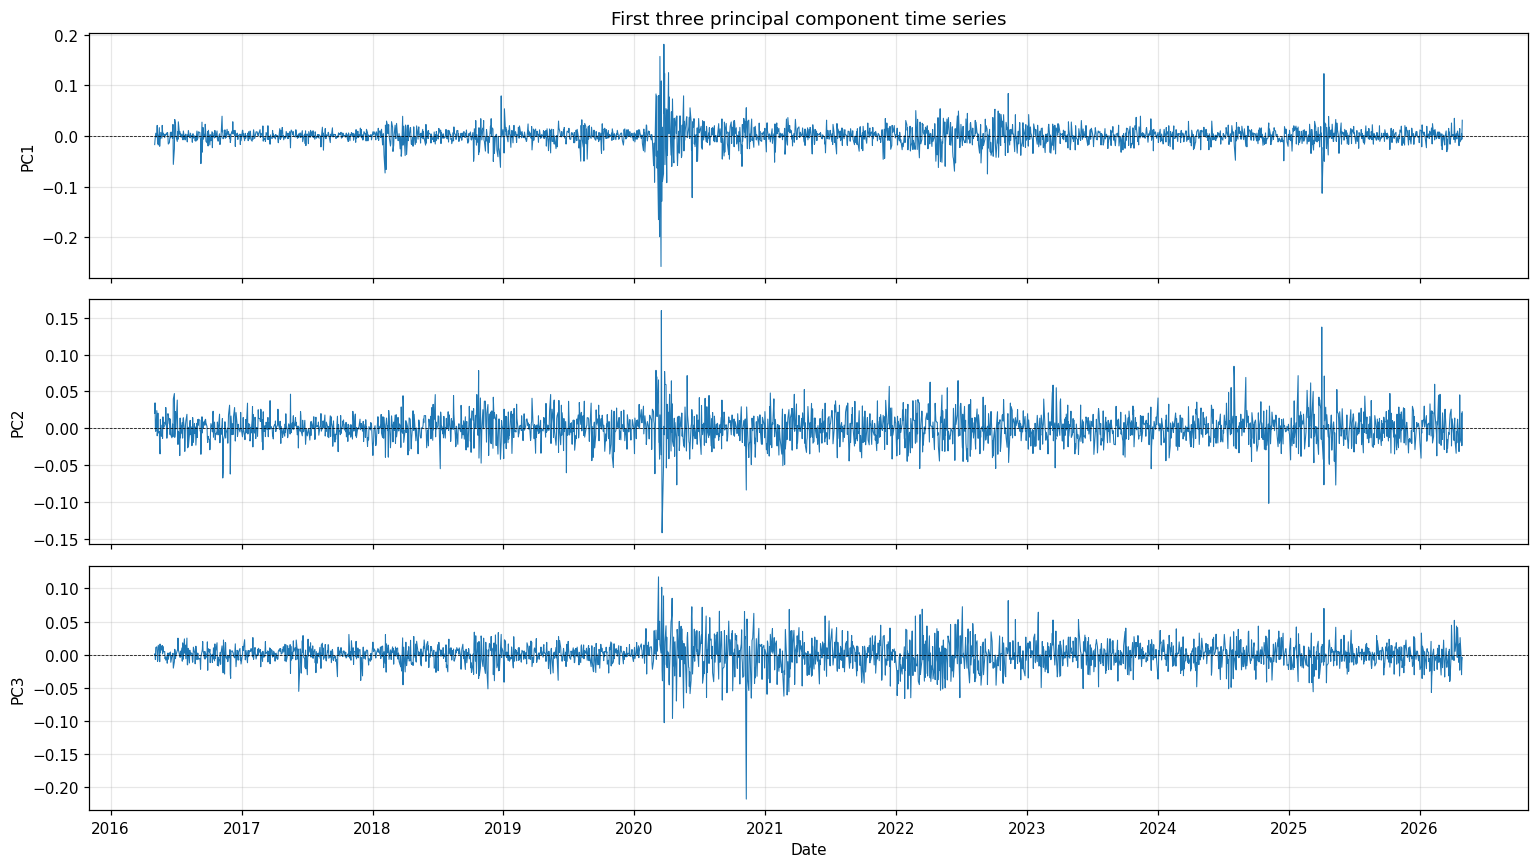

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(dates, Vt[i], linewidth=0.7)
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.set_ylabel(f"PC{i+1}")
axes[0].set_title("First three principal component time series")
axes[-1].set_xlabel("Date")
plt.tight_layout(); plt.show()

All three components show their largest swings in **March 2020 (COVID crash)**, when nearly every stock moved together and correlations jumped. Other episodes stand out:

- **PC1** (the market factor) is noticeably more volatile throughout **2022** (the Fed's rate-hiking cycle) and spikes again in **April 2025**, during the tariff announcements and the reversal that followed.
- **PC3** has its single largest move in **November 2020**, which lines up with the vaccine-announcement rotation: energy and other reopening stocks rallied while tech sold off. The sector loadings below show PC3 is essentially a tech-versus-energy factor, which explains why it reacted so strongly.
- **PC2** has a sharp move in **November 2024**, around the US election, when cyclicals and financials rallied relative to defensive sectors.

## What each component represents: average loading by sector

A stock's loading on a component, $U_{ij}\sigma_j / \sqrt{T-1}$, is approximately its correlation with that component's time series. Averaging the loadings within each sector shows what each component picks up.

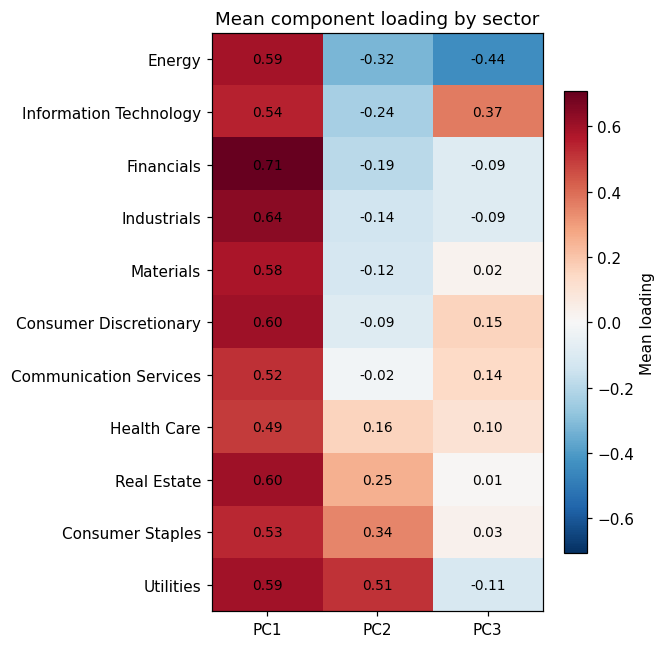

In [8]:
n_days = X.shape[1]
loadings = pd.DataFrame(U[:, :3] * s[:3] / np.sqrt(n_days - 1),
                        index=tickers_final, columns=["PC1", "PC2", "PC3"])
sector_loadings = loadings.groupby(sectors_final).mean().sort_values("PC2")

fig, ax = plt.subplots(figsize=(6, 6))
lim = np.abs(sector_loadings.values).max()
im = ax.imshow(sector_loadings.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(sector_loadings.columns)
ax.set_yticks(range(len(sector_loadings))); ax.set_yticklabels(sector_loadings.index)
ax.grid(False)
for (r, c), v in np.ndenumerate(sector_loadings.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8, label="Mean loading")
ax.set_title("Mean component loading by sector")
plt.tight_layout(); plt.show()

- **PC1 is the market factor.** Every sector loads positively, with average loadings between about 0.5 and 0.7. Financials and industrials load highest, and health care loads lowest.
- **PC2 is defensive vs cyclical.** Utilities, consumer staples and real estate (rate-sensitive, 'bond-like' sectors) load positively. Energy, technology and financials load negatively.
- **PC3 is growth vs commodities.** Information technology loads strongly positive and energy strongly negative, with most other sectors near zero.

This explains why energy and utilities sit at opposite ends of the embeddings below: they lie on opposite sides of the two main non-market factors.

## Dimensionality reduction: PCA vs t-SNE vs UMAP

Each stock is represented by its scores on the **first 10 principal components** (about the level where the scree plot flattens). t-SNE and UMAP then compress those 10 dimensions to 2. Running them on only the first 3 components would just re-arrange the PCA plot, so they get more dimensions to work with.

**Hyperparameters:** t-SNE perplexity = 10 and UMAP `n_neighbors` = 10 with `min_dist` = 0.2. With only 100 points and about 9 stocks per sector, a neighborhood of roughly one sector's size keeps the focus local.

To measure clustering instead of judging it by eye, the **k-NN sector purity** is computed for each representation: the fraction of each stock's 5 nearest neighbors that belong to the same sector. If sectors were assigned at random, the expected purity would be about 0.08.

5-NN sector purity:
PCA (10 components)    0.673
PCA (PC2 vs PC3)       0.373
t-SNE                  0.700
UMAP                   0.665
Random (chance)        0.082


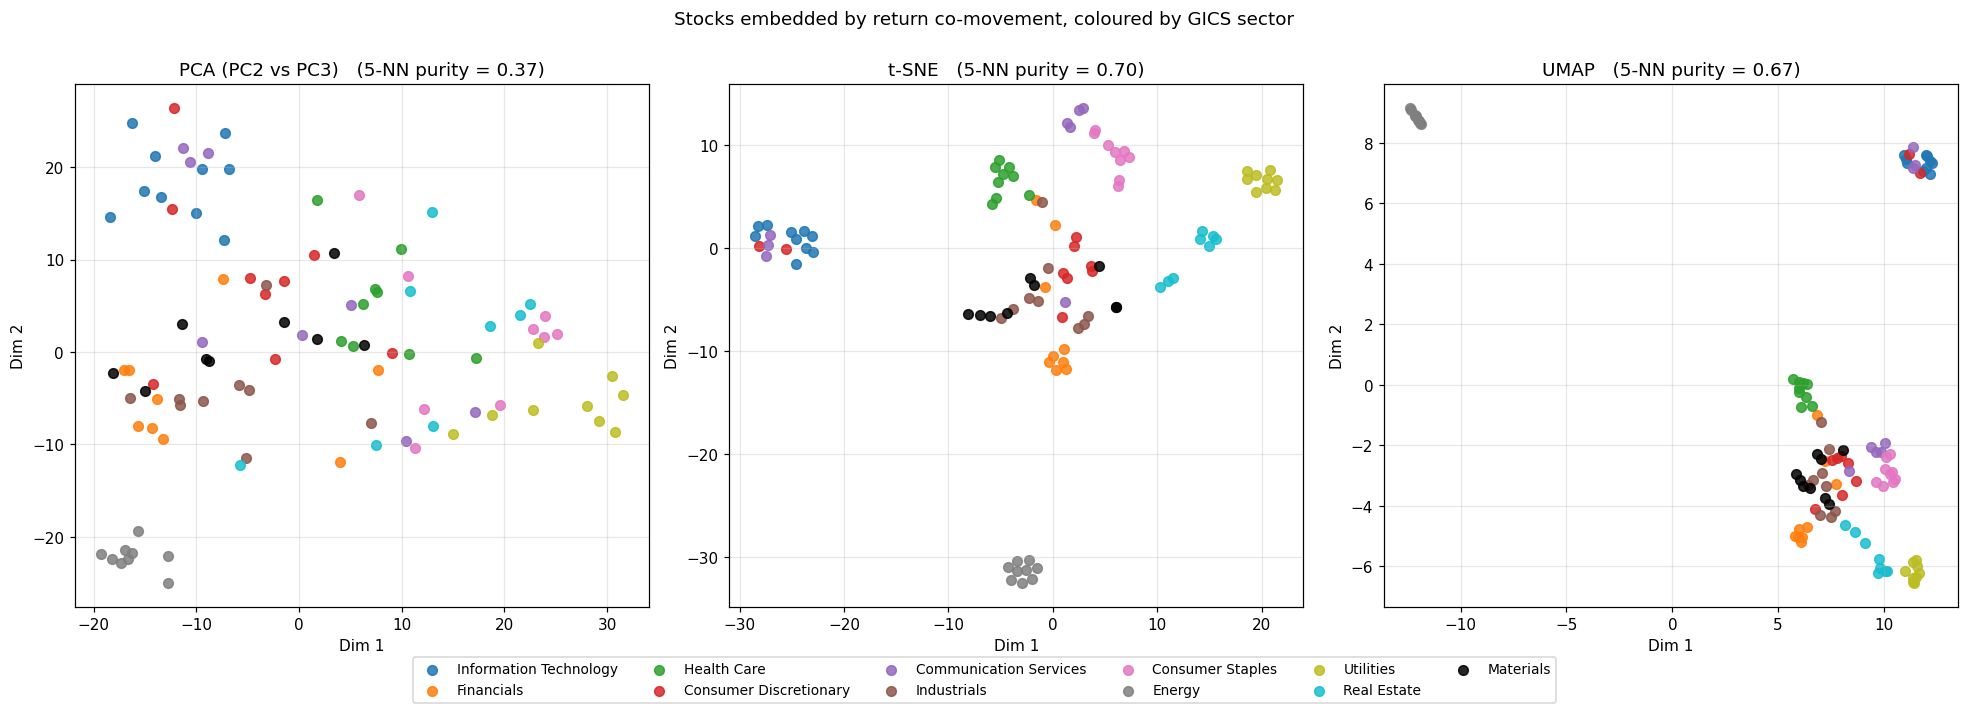

In [9]:
N_PCS_EMBED = 10
pc_scores = U[:, :N_PCS_EMBED] * s[:N_PCS_EMBED]

tsne_2d = TSNE(n_components=2, perplexity=10, init="pca", random_state=SEED).fit_transform(pc_scores)
umap_2d = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.2, random_state=SEED).fit_transform(pc_scores)


def knn_sector_purity(coords, sectors, k=5):
    # Fraction of each point's k nearest neighbours (excluding itself) that share its sector.
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(coords).kneighbors(coords)
    return float((sectors[idx[:, 1:]] == sectors[:, None]).mean())


counts = pd.Series(sectors_final).value_counts().values
n_stocks = len(sectors_final)
chance_purity = float((counts * (counts - 1)).sum() / (n_stocks * (n_stocks - 1)))

representations = {
    "PCA (10 components)": pc_scores,
    "PCA (PC2 vs PC3)": pc_scores[:, 1:3],
    "t-SNE": tsne_2d,
    "UMAP": umap_2d,
}
purity = pd.Series({name: knn_sector_purity(c, sectors_final) for name, c in representations.items()})
purity["Random (chance)"] = chance_purity
print("5-NN sector purity:")
print(purity.round(3).to_string())

# 11 sectors need 11 distinct colours (the default cycle only has 10)
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b",
           "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#000000"]
sector_colors = dict(zip(TICKERS_BY_SECTOR, palette))

plots = {"PCA (PC2 vs PC3)": pc_scores[:, 1:3], "t-SNE": tsne_2d, "UMAP": umap_2d}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (title, coords) in zip(axes, plots.items()):
    for sector, color in sector_colors.items():
        m = sectors_final == sector
        ax.scatter(coords[m, 0], coords[m, 1], color=color, label=sector, s=40, alpha=0.85)
    ax.set_title(f"{title}   (5-NN purity = {purity[title]:.2f})")
    ax.set_xlabel("Dim 1"); ax.set_ylabel("Dim 2")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.suptitle("Stocks embedded by return co-movement, coloured by GICS sector", y=1.0)
plt.tight_layout(); plt.show()

**Sectors are clearly visible in return co-movement.** In the full 10-component PCA space, about two-thirds of each stock's 5 nearest neighbours are in its own sector (purity 0.67), roughly 8x the 0.08 expected by chance. t-SNE and UMAP (both about 0.67–0.70; t-SNE varies slightly between runs) keep that local structure almost exactly while compressing it to 2 dimensions. A 2-D slice of PCA (PC2 vs PC3) keeps much less of it (0.37), because the sector information is spread across many components.

What the embeddings show:
- **Energy** forms the most distinct cluster in every view. UMAP places it far from all other stocks.
- **Utilities, real estate, consumer staples and health care** also form tight, separate groups.
- **Information Technology and Communication Services merge into one cluster.** Names like GOOGL, META and NFLX trade like tech stocks, whatever their GICS label says.
- **Consumer Discretionary is the least coherent sector.** It's split between tech-like names (AMZN, TSLA) and retailers that sit near industrials and materials.

In short, GICS sectors are a strong but imperfect description of how stocks actually move. The market factor dominates overall variance, but once it is accounted for, sector membership is the main structure left over.

# Part 2: Predicting BTC vs ETH Relative Returns

**Question:** given the last 7 days of BTC and ETH log returns, can we predict whether **BTC will outperform ETH tomorrow**? This is a binary classification of *which* asset does better, not a prediction of the size of the gap.

For each day $t$:
- **Features:** BTC and ETH log returns on days $t-1, \dots, t-7$ (14 features). All of these are known at the close of day $t-1$.
- **Target:** $y_t = 1$ if BTC's log return on day $t$ is greater than ETH's, otherwise 0.

Yahoo's ETH-USD history begins in November 2017, so the usable sample starts then.

In [10]:
crypto = download_close(["BTC-USD", "ETH-USD"]).rename(columns={"BTC-USD": "BTC", "ETH-USD": "ETH"})
print(f"Missing values: {crypto.isna().sum().to_dict()}")
crypto = crypto.dropna()
crypto_ret = np.log(crypto / crypto.shift(1)).dropna()
print(f"Daily returns: {len(crypto_ret)} days ({crypto_ret.index[0].date()} to {crypto_ret.index[-1].date()})")


def make_lag_features(returns, n_lags=N_LAGS):
    # Row t: returns on days t-1 .. t-n_lags. Target: 1 if BTC's return beats ETH's on day t.
    features = pd.DataFrame({f"{asset.lower()}_lag{k}": returns[asset].shift(k)
                             for asset in ["BTC", "ETH"] for k in range(1, n_lags + 1)})
    target = (returns["BTC"] > returns["ETH"]).astype(int).rename("btc_outperforms")
    data = pd.concat([features, target], axis=1).dropna()
    return data.drop(columns=target.name), data[target.name]


X2, y2 = make_lag_features(crypto_ret)
print(f"Feature matrix: {X2.shape}, target: {y2.shape}")

Missing values: {'BTC': 0, 'ETH': 557}
Daily returns: 3094 days (2017-11-10 to 2026-04-30)
Feature matrix: (3087, 14), target: (3087,)


## Chronological train / validation / test split

The data is split 60 / 20 / 20 **in time order**, with no shuffling, so every model is trained on the past and evaluated on the future. Hyperparameters are chosen on validation, and the test set is used only once, for the final comparison.

In [11]:
n = len(X2)
train_end, val_end = int(n * 0.60), int(n * 0.80)
X_train, y_train = X2.iloc[:train_end], y2.iloc[:train_end]
X_val,   y_val   = X2.iloc[train_end:val_end], y2.iloc[train_end:val_end]
X_test,  y_test  = X2.iloc[val_end:], y2.iloc[val_end:]

for name, Xs, ys in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:>5}: n={len(ys):4d}  {Xs.index[0].date()} to {Xs.index[-1].date()}  "
          f"P(BTC outperforms)={ys.mean():.3f}")

Train: n=1852  2017-11-17 to 2022-12-12  P(BTC outperforms)=0.525
  Val: n= 617  2022-12-13 to 2024-08-20  P(BTC outperforms)=0.556
 Test: n= 618  2024-08-21 to 2026-04-30  P(BTC outperforms)=0.553


The classes are roughly balanced: BTC outperforms on 52.5% of training days and about 55% of validation and test days. The base rate is stable across periods, so there is no major distribution shift between the splits. Since BTC wins more often in every split, the naive baseline is fairly strong.

## Naive baseline

The baseline always predicts the **majority class from the training set**. Only training labels are used to choose it, so it gets no information from the validation or test periods. Every model has to beat this to show it has learned anything.

In [12]:
def error_rate(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) != np.asarray(y_pred)))


majority_class = int(y_train.mean() >= 0.5)
predictions = {"Naive Baseline": {split: np.full(len(Xs), majority_class)
                                  for split, Xs in [("train", X_train), ("val", X_val), ("test", X_test)]}}
print(f"Training majority class: {majority_class} "
      f"({'BTC' if majority_class else 'ETH'} outperforms)")

Training majority class: 1 (BTC outperforms)


## Model definitions

Daily log returns are on the order of 0.01–0.05. Without scaling, the regularization penalty in logistic regression barely affects the coefficients, and neural-network training is poorly conditioned. **Logistic regression and the neural network therefore standardize their inputs with a scaler fitted on the training data only.** Tree-based models don't depend on feature scale, so they use the raw returns.

In [13]:
C_VALUES = np.logspace(-3, 2, 11)


def make_logreg(C):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=C,
                           max_iter=5000, random_state=SEED),
    )


def make_rf():
    return RandomForestClassifier(n_estimators=200, max_depth=2, random_state=SEED, n_jobs=-1)


def make_xgb():
    return XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05,
                         random_state=SEED, verbosity=0, n_jobs=1)


class Net(nn.Module):
    # One-hidden-layer MLP that outputs a logit.
    def __init__(self, n_features, hidden=11):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_features, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.layers(x)


def train_net(X_tr, y_tr, X_va, y_va, max_epochs=500, patience=20, lr=1e-3, seed=SEED):
    # Full-batch Adam with early stopping on validation loss. Returns (predict_fn, best_epoch).
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(X_tr)
    as_tensor = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
    Xt, Xv = as_tensor(scaler.transform(X_tr)), as_tensor(scaler.transform(X_va))
    yt, yv = as_tensor(y_tr).unsqueeze(1), as_tensor(y_va).unsqueeze(1)

    model = Net(Xt.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        loss_fn(model(Xt), yt).backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), yv).item()
        if val_loss < best_loss:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()

    def predict(X):
        with torch.no_grad():
            return (model(as_tensor(scaler.transform(X))) > 0).int().numpy().ravel()

    return predict, best_epoch


def predict_splits(predict_fn):
    return {"train": predict_fn(X_train), "val": predict_fn(X_val), "test": predict_fn(X_test)}

## Logistic regression (elastic net)

The regularization strength $C$ is tuned on the validation set over a log-spaced grid from $10^{-3}$ to $10^{2}$. At small $C$ every coefficient is shrunk to zero, so the model always predicts the majority class.

Best C: 1 | validation error: 0.4392


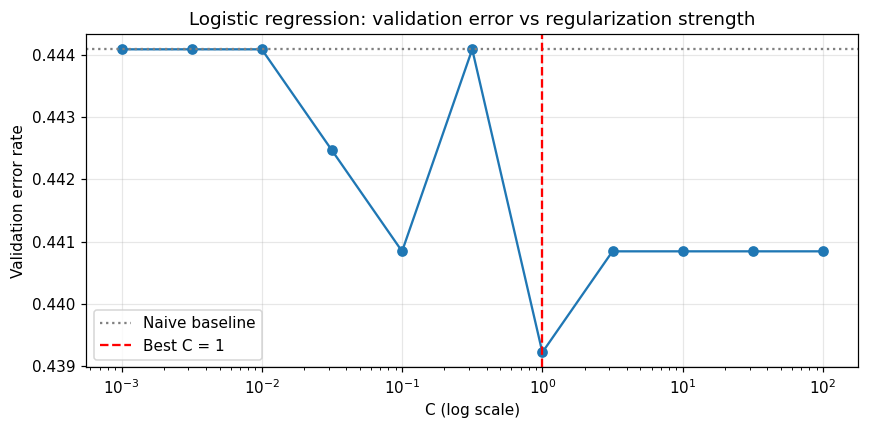

Non-zero coefficients: 14 / 14


In [14]:
val_errors = [error_rate(y_val, make_logreg(C).fit(X_train, y_train).predict(X_val)) for C in C_VALUES]
best_C = float(C_VALUES[int(np.argmin(val_errors))])
print(f"Best C: {best_C:.4g} | validation error: {min(val_errors):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(C_VALUES, val_errors, marker="o")
ax.axhline(error_rate(y_val, predictions["Naive Baseline"]["val"]), color="gray", linestyle=":",
           label="Naive baseline")
ax.axvline(best_C, color="red", linestyle="--", label=f"Best C = {best_C:.3g}")
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("Validation error rate")
ax.set_title("Logistic regression: validation error vs regularization strength")
ax.legend(); plt.tight_layout(); plt.show()

logreg = make_logreg(best_C).fit(X_train, y_train)
predictions["Logistic Regression"] = predict_splits(logreg.predict)
coefs = pd.Series(logreg[-1].coef_.ravel(), index=X2.columns)
print(f"Non-zero coefficients: {(coefs != 0).sum()} / {len(coefs)}")

The validation error varies only between 0.439 and 0.444 across the entire grid, a spread of about 3 days out of 617. The best $C$ is therefore not meaningfully better than the others, including the heavily regularized models that always predict the majority class. This is a first sign that the lagged returns carry very little usable signal.

## Random forest and XGBoost

Shallow trees (`max_depth=2`) are used for both bagging and boosting to limit overfitting on a noisy target.

In [15]:
rf_model = make_rf().fit(X_train, y_train)
predictions["Random Forest"] = predict_splits(rf_model.predict)

xgb_model = make_xgb().fit(X_train, y_train)
predictions["XGBoost"] = predict_splits(xgb_model.predict)

for name in ["Random Forest", "XGBoost"]:
    p = predictions[name]
    print(f"{name:>14}: train {error_rate(y_train, p['train']):.4f} | "
          f"val {error_rate(y_val, p['val']):.4f} | test {error_rate(y_test, p['test']):.4f}")

 Random Forest: train 0.4152 | val 0.4587 | test 0.4644
       XGBoost: train 0.3251 | val 0.4652 | test 0.4887


Both tree ensembles fit the training data noticeably better than they generalize. XGBoost overfits the most: its training error is 0.33, but its test error is 0.49, worse than always predicting BTC.

## Neural network

A small PyTorch MLP (14 → 11 → 1), trained full-batch with Adam and early stopping on validation loss.

In [16]:
nn_predict, nn_best_epoch = train_net(X_train, y_train, X_val, y_val)
predictions["Neural Network"] = predict_splits(nn_predict)
n_params = sum(p.numel() for p in Net(X2.shape[1]).parameters())
p = predictions["Neural Network"]
print(f"Parameters: {n_params} | best epoch: {nn_best_epoch}")
print(f"Neural Net: train {error_rate(y_train, p['train']):.4f} | "
      f"val {error_rate(y_val, p['val']):.4f} | test {error_rate(y_test, p['test']):.4f}")

Parameters: 177 | best epoch: 296
Neural Net: train 0.4217 | val 0.4765 | test 0.4628


## Model comparison on the held-out test set

For each model, the table shows its error rates, a 95% confidence interval for test accuracy, and a one-sided **binomial test** of whether its test accuracy beats the baseline's. With roughly 600 test days, the standard error of an accuracy estimate is about ±2 percentage points, so small differences between models are within noise.

In [17]:
baseline_test_acc = 1 - error_rate(y_test, predictions["Naive Baseline"]["test"])
rows = {}
for name, p in predictions.items():
    correct = int((p["test"] == y_test.values).sum())
    test = binomtest(correct, len(y_test), p=baseline_test_acc, alternative="greater")
    ci = binomtest(correct, len(y_test)).proportion_ci(confidence_level=0.95)   # two-sided CI
    rows[name] = {
        "Train Error": error_rate(y_train, p["train"]),
        "Val Error": error_rate(y_val, p["val"]),
        "Test Error": error_rate(y_test, p["test"]),
        "Test Acc 95% CI": f"[{ci.low:.3f}, {ci.high:.3f}]",
        "p (beats baseline)": np.nan if name == "Naive Baseline" else test.pvalue,
    }
results = pd.DataFrame(rows).T
print(results.to_string(float_format=lambda v: f"{v:.4f}"))

                    Train Error Val Error Test Error Test Acc 95% CI p (beats baseline)
Naive Baseline           0.4746    0.4441     0.4466  [0.513, 0.593]                NaN
Logistic Regression      0.4681    0.4392     0.4628  [0.497, 0.577]             0.8023
Random Forest            0.4152    0.4587     0.4644  [0.495, 0.575]             0.8240
XGBoost                  0.3251    0.4652     0.4887  [0.471, 0.551]             0.9838
Neural Network           0.4217    0.4765     0.4628  [0.497, 0.577]             0.8023


**No model beats the naive baseline on the test set.** Every model's test error is equal to or higher than the baseline's 0.447, and every p-value is far above 0.05. All the confidence intervals overlap, so none of the models can be told apart from the others statistically. XGBoost again shows the clearest overfitting: the lowest training error and the highest test error.

## Robustness check: walk-forward validation

A single test window can be lucky or unlucky. With `TimeSeriesSplit` (5 folds), each fold trains on all data before a test window and then evaluates on that window, moving forward through time. In every fold:
- the baseline is the majority class of that fold's training data;
- logistic regression's $C$ is re-tuned, and the neural network is early-stopped, using only the last 20% of that fold's training data, so no tuning sees the test window.

Pooling the out-of-sample predictions from all folds gives a larger test sample and a more powerful binomial test.

In [18]:
def fit_predict_all(X_tr, y_tr, X_te):
    # Fit every model on X_tr (tuning on its last 20%) and return predictions for X_te.
    cut = int(len(X_tr) * 0.8)
    X_fit, y_fit, X_in, y_in = X_tr.iloc[:cut], y_tr.iloc[:cut], X_tr.iloc[cut:], y_tr.iloc[cut:]

    inner_errors = [error_rate(y_in, make_logreg(C).fit(X_fit, y_fit).predict(X_in)) for C in C_VALUES]
    C = C_VALUES[int(np.argmin(inner_errors))]
    nn_fn, _ = train_net(X_fit, y_fit, X_in, y_in)

    return {
        "Naive Baseline": np.full(len(X_te), int(y_tr.mean() >= 0.5)),
        "Logistic Regression": make_logreg(C).fit(X_tr, y_tr).predict(X_te),
        "Random Forest": make_rf().fit(X_tr, y_tr).predict(X_te),
        "XGBoost": make_xgb().fit(X_tr, y_tr).predict(X_te),
        "Neural Network": nn_fn(X_te),
    }


fold_errors, oos_preds, oos_true = [], {}, []
for fold, (tr_idx, te_idx) in enumerate(TimeSeriesSplit(n_splits=5).split(X2), start=1):
    X_tr, y_tr, X_te, y_te = X2.iloc[tr_idx], y2.iloc[tr_idx], X2.iloc[te_idx], y2.iloc[te_idx]
    fold_pred = fit_predict_all(X_tr, y_tr, X_te)
    fold_errors.append({name: error_rate(y_te, p) for name, p in fold_pred.items()})
    for name, p in fold_pred.items():
        oos_preds.setdefault(name, []).append(p)
    oos_true.append(y_te.values)
    print(f"Fold {fold}: train n={len(tr_idx):4d}, test {X_te.index[0].date()} to {X_te.index[-1].date()}")

oos_true = np.concatenate(oos_true)
oos_preds = {name: np.concatenate(p) for name, p in oos_preds.items()}
fold_errors = pd.DataFrame(fold_errors, index=[f"Fold {i}" for i in range(1, 6)])

baseline_oos_acc = 1 - error_rate(oos_true, oos_preds["Naive Baseline"])
wf = pd.DataFrame({
    "Pooled OOS Error": {k: error_rate(oos_true, p) for k, p in oos_preds.items()},
    "p (beats baseline)": {
        k: np.nan if k == "Naive Baseline" else
        binomtest(int((p == oos_true).sum()), len(oos_true), p=baseline_oos_acc, alternative="greater").pvalue
        for k, p in oos_preds.items()
    },
    "Std Across Folds": fold_errors.std(),
})
print(f"\nPooled out-of-sample predictions: n={len(oos_true)}\n")
print(wf.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nError by fold:\n" + fold_errors.to_string(float_format=lambda v: f"{v:.4f}"))

Fold 1: train n= 517, test 2019-04-18 to 2020-09-12
Fold 2: train n=1031, test 2020-09-13 to 2022-02-08
Fold 3: train n=1545, test 2022-02-09 to 2023-07-07
Fold 4: train n=2059, test 2023-07-08 to 2024-12-02
Fold 5: train n=2573, test 2024-12-03 to 2026-04-30

Pooled out-of-sample predictions: n=2570

                     Pooled OOS Error  p (beats baseline)  Std Across Folds
Naive Baseline                 0.4642                 NaN            0.0322
Logistic Regression            0.4767              0.9006            0.0349
Random Forest                  0.4704              0.7431            0.0343
XGBoost                        0.4778              0.9198            0.0229
Neural Network                 0.5070              1.0000            0.0355

Error by fold:
        Naive Baseline  Logistic Regression  Random Forest  XGBoost  Neural Network
Fold 1          0.4864               0.4981         0.4981   0.5117          0.4650
Fold 2          0.4533               0.4981         0.449

The walk-forward results confirm the single-split result across five different periods covering 2019 to 2026:

- **The training-majority baseline has the lowest pooled out-of-sample error (0.464).** No model beats it significantly (all p > 0.7), and the neural network does worse than a coin flip overall.
- **The variation between folds is larger than the differences between models.** The baseline's error ranges from 0.42 to 0.50 depending on the period, because the share of days BTC wins changes over time. The main thing that decides accuracy is which coin is in a winning phase, not the model.

# Conclusions

**Sector structure (Part 1)**
- A single market factor explains about 35% of daily excess-return variance in large-cap US stocks. The next two factors are interpretable: defensive vs cyclical (PC2) and technology vs energy (PC3).
- GICS sectors are clearly visible in return co-movement. A stock's nearest neighbours are in its own sector about two-thirds of the time, against about 8% by chance. The boundaries are imperfect: tech and communication services behave as one group, and consumer discretionary splits apart.
- Once the nonlinear methods get enough principal components to work with, they don't find more sector structure than PCA. They mainly make the existing structure easier to see in 2 dimensions.

**BTC vs ETH prediction (Part 2)**
- Seven days of lagged returns do **not** predict whether BTC will outperform ETH the next day. Across logistic regression, random forest, XGBoost and a neural network, no model significantly beats always predicting the historically more frequent outcome, on either the held-out test set or in walk-forward validation.
- This fits the weak-form efficient-market hypothesis for liquid crypto assets at a daily horizon. More flexible models (XGBoost, the neural network) only add overfitting.

# Limitations

- **Survivorship bias:** the stock universe consists of today's large caps, chosen in hindsight. Two tickers on the original list (EA and AVB) are no longer served by Yahoo Finance and were dropped.
- **Data drift:** Yahoo Finance revises adjusted prices and removes delisted tickers, so re-running this notebook later can change the numbers.
- **Static analysis:** the PCA is fitted over the full ten years. Factor structure changes over time (for example, correlations rise sharply in crises), and a rolling-window PCA would capture that.
- **Narrow feature set:** Part 2 only tests lagged returns. Volume, volatility, funding rates or on-chain data might carry signal, but they are outside the scope of this analysis.
- **No trading costs:** even a model that beat the baseline would also need to clear transaction costs to be useful in practice.